In [1]:
import pandas as pd

df = pd.read_csv('Dataset_cleaned.csv', parse_dates=['date_added'])
print(df.shape)

(8787, 12)


In [2]:
print(df['country'].head(10).tolist())

['United States', 'France', 'United States', 'Brazil', 'United States', 'United Kingdom', 'United States', 'India', 'Germany', 'India']


In [3]:
country_split = df['country'].str.split(',')
country_exploded = country_split.explode().str.strip()

print("Rows before:", len(df))
print("Rows after exploding:", len(country_exploded))
print(country_exploded.head(10).tolist())

Rows before: 8787
Rows after exploding: 8787
['United States', 'France', 'United States', 'Brazil', 'United States', 'United Kingdom', 'United States', 'India', 'Germany', 'India']


In [4]:
has_comma = df['country'].str.contains(',', na=False)
print("Rows with multiple countries:", has_comma.sum())
print(df.loc[has_comma, 'country'].head(10).tolist())

Rows with multiple countries: 0
[]


In [5]:
print("Unknown country rows:", (df['country'] == 'Unknown').sum())

Unknown country rows: 287


In [6]:
known_country = df[df['country'] != 'Unknown']
print("Rows with a known country:", len(known_country))

Rows with a known country: 8500


In [7]:
country_counts = known_country['country'].value_counts()
print(country_counts.head(10))

country
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

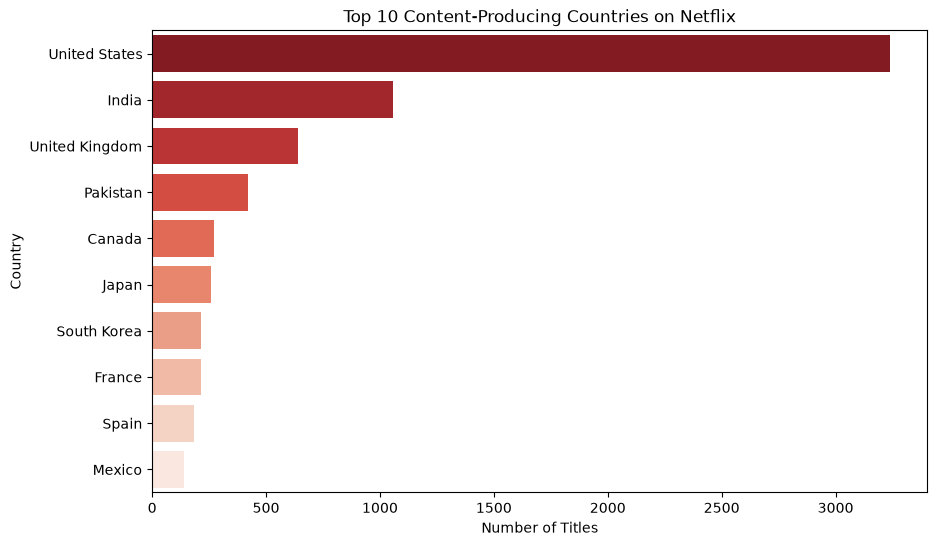

In [9]:
plt.figure(figsize=(10, 6))
top10 = country_counts.head(10)
sns.barplot(x=top10.values, y=top10.index, hue=top10.index, palette='Reds_r', legend=False)
plt.title('Top 10 Content-Producing Countries on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.show()

In [10]:
top5_countries = country_counts.head(5).index.tolist()
top5_data = known_country[known_country['country'].isin(top5_countries)]

type_by_country = top5_data.groupby(['country', 'type']).size().unstack(fill_value=0)
type_by_country = type_by_country.loc[top5_countries]
print(type_by_country)

type            Movie  TV Show
country                       
United States    2395      845
India             975       81
United Kingdom    387      251
Pakistan           71      349
Canada            187       84


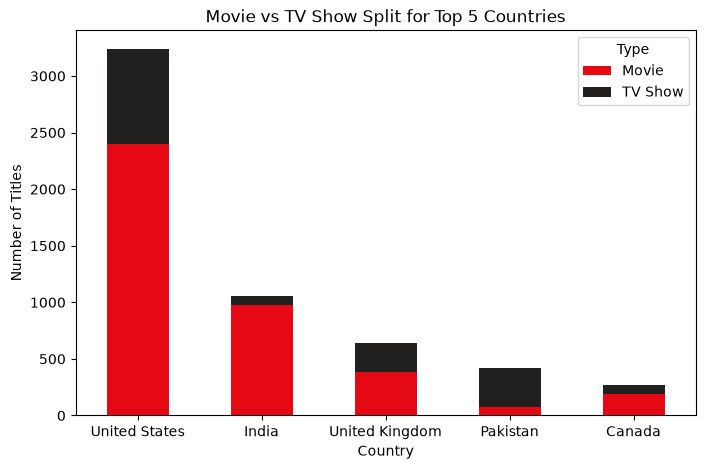

In [11]:
type_by_country.plot(kind='bar', stacked=True, color=['#E50914', '#221f1f'], figsize=(8, 5))
plt.title('Movie vs TV Show Split for Top 5 Countries')
plt.xlabel('Country')
plt.ylabel('Number of Titles')
plt.xticks(rotation=0)
plt.legend(title='Type')
plt.show()

## Task 3: Country-Wise Netflix Content Analysis - Summary

### Objective
Analyze Netflix content availability across different countries.

### Method Notes
- The `country` field contains exactly one country per title in this dataset (no co-productions to split).
- 287 titles had no country listed (labeled 'Unknown' in Task 1) and were excluded from country-level rankings, since they don't represent an actual country. 8,500 titles had a known country.

### Key Findings
1. **Top content-producing countries:** United States (3,240 titles) and India (1,056) lead by a wide margin, together accounting for over half of all titles with a known country. United Kingdom (638), Pakistan (420) and Canada (271) round out the top 5.
2. **Content type varies sharply by country.** Among the top 5:
   - **India** is overwhelmingly Movie-focused (~92% Movies, 975 vs 81 TV Shows).
   - **Pakistan** is the opposite: ~83% TV Shows (349 vs 71 Movies), the only top-5 country where TV Shows dominate.
   - The United States, United Kingdom and Canada fall in between, each still Movie-majority (61-74%) but with a meaningful TV Show presence.

### Business Insight
Content strategy should not be one-size-fits-all across regions. India's catalog suggests Movies are the stronger growth lever there, while Pakistan shows the opposite: TV Show content already resonates far more than Movies. Country-specific content investment is likely to outperform a uniform global approach.
